# 현실의 데이터 35: 리그 오브 레전드 e스포츠: 밴픽 끝, 누가 이길까?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/35_lol_esports.ipynb)

**분야**: 스포츠 · 게임 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: e스포츠 데이터 · 실시간 승률 예측 (중계) · 팀 실력 (Elo 레이팅)

> 프로 경기 13만 판. 밴픽이 끝난 순간, 블루 팀이 이길지 맞힐 수 있을까?

**데이터**: LoL 프로 경기 기록 (2011 ~ 2026) (약 12MB). Leaguepedia (lol.fandom.com) 의 프로 경기 기록을 GPTilt 가 정리해 Hugging Face 에 올린 것 (gptilt/lol-esports-matches). 한 판마다 날짜 · 대회 · 두 팀 · 이긴 팀 · 양 팀 챔피언 5개 · 밴 · 경기 시간. 라이선스 CC BY-SA 3.0.

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 경기 한 판 |
| ② 입력 X | 두 팀의 그 경기 전까지 실력 (Elo 레이팅) · 양 팀이 고른 챔피언 10개 |
| ③ 출력 y | 블루 팀이 이기나 (확률) |
| ④ 평가지표 | 정확도, 로그 손실 |
| ⑤ 기준선 | 늘 블루 승 (약 53%) |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Guan & Tung (2026) Pre-game paired-comparison modeling of professional League of Legends map outcomes](https://arxiv.org/abs/2609.08060)
- [Do et al. (2021) Using Machine Learning to Predict Game Outcomes Based on Player-Champion Experience in League of Legends, FDG](https://arxiv.org/abs/2108.02799)
- [Leaguepedia: 경기 기록 원본 (CC BY-SA 3.0)](https://lol.fandom.com/)
- [Hugging Face 데이터 설명 (gptilt/lol-esports-matches)](https://huggingface.co/datasets/gptilt/lol-esports-matches)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

표 두 개: 경기 한 판마다 한 줄 (`games`), 대회마다 한 줄 (`tournaments`, 지역 · 등급). 대회 등급이 Primary (각 지역 1부 리그 · 국제 대회) 또는 Secondary (2부 · 아카데미) 인 경기만 쓰고 이벤트 경기 (Showmatch) 는 뺀다.

출처: Leaguepedia (lol.fandom.com), CC BY-SA 3.0.

In [2]:
BASE = "https://huggingface.co/datasets/gptilt/lol-esports-matches/resolve/main/"
games = pd.read_parquet(download(BASE + "games/games.parquet", "data/lol/games.parquet"))
tours = pd.read_parquet(download(BASE + "tournaments/tournaments.parquet", "data/lol/tournaments.parquet"))

games = games.merge(tours[["tournament_id", "region", "tier"]], left_on="tournament", right_on="tournament_id", how="left")
games = games[games["tier"].isin(["Primary", "Secondary"])].sort_values("datetime_utc").reset_index(drop=True)
games["blue_win"] = (games["winner"] == games["team_blue"]).astype(int)
games["year"] = games["datetime_utc"].str[:4].astype(int)
print(games.shape, "| teams", games["team_blue"].nunique(), "| blue side won", f"{games['blue_win'].mean():.1%}")
games[["datetime_utc", "tournament", "team_blue", "team_red", "winner", "picks_blue", "picks_red", "gamelength"]].tail(5)

(137493, 22) | teams 4409 | blue side won 53.2%


,datetime_utc,tournament,team_blue,team_red,winner,picks_blue,picks_red,gamelength
137488,2026-10-04 06:16:00,LCK Academy Series/2026 Season/2nd Championship,Eunpyeong Meditech High School,Nongshim RedForce Academy,Nongshim RedForce Academy,"[K'Sante, Aatrox, Ryze, Yunara, Lulu]","[Gnar, Wukong, Syndra, Lucian, Milio]",31:10
137489,2026-10-04 06:22:00,LCK Academy Series/2026 Season/2nd Championship,KT Rolster Academy,Dplus Kia Youth,Dplus Kia Youth,"[Olaf, Xin Zhao, Cassiopeia, Varus, Alistar]","[Jax, Wukong, Orianna, Aphelios, Renata Glasc]",25:30
137490,2026-10-04 06:54:00,LCK Academy Series/2026 Season/2nd Championship,Hanwha Life Esports Academy,Gen.G Scholars,Hanwha Life Esports Academy,"[Jayce, Lee Sin, Twisted Fate, Ezreal, Bard]","[Olaf, Qiyana, Ryze, Jhin, Nautilus]",27:08
137491,2026-10-04 07:07:00,LCK Academy Series/2026 Season/2nd Championship,Nongshim RedForce Academy,Eunpyeong Meditech High School,Nongshim RedForce Academy,"[Rumble, Xin Zhao, Viktor, Miss Fortune, Neeko]","[Sion, Qiyana, Lissandra, Kalista, Renata Glasc]",24:52
137492,2026-10-04 07:08:00,LCK Academy Series/2026 Season/2nd Championship,HANJIN BRION Academy,DN SOOPers Academy,DN SOOPers Academy,"[Jayce, Aatrox, Lissandra, Caitlyn, Elise]","[Gragas, Wukong, Viktor, Xayah, Rakan]",29:06


## 열어 보기: 블루 진영 이점과 인기 챔피언

- 해마다 블루 진영 (맵 왼쪽 아래) 은 몇 % 이겼을까? 야구의 홈 이점과 비슷하다.
- 최근 두 해에 가장 많이 고른 챔피언과, 그 챔피언을 고른 팀의 승률.

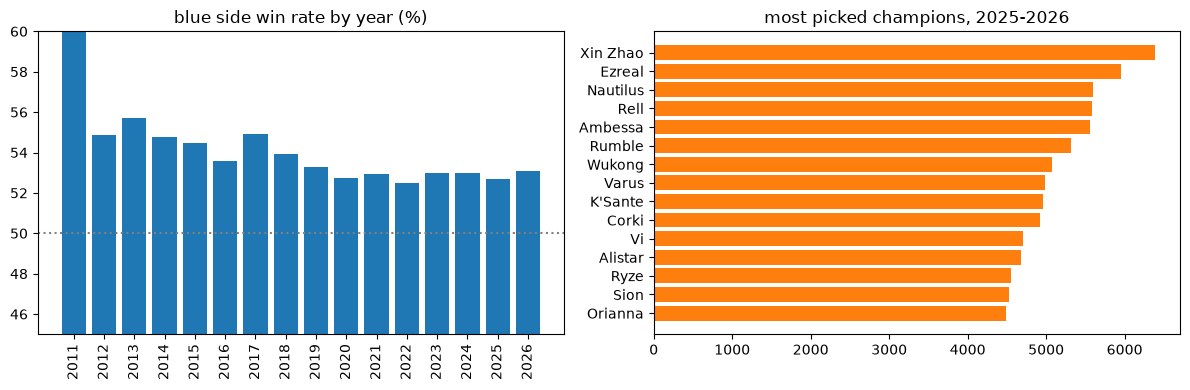

          picks  win_rate
champ                    
Xin Zhao   6386     0.487
Ezreal     5953     0.486
Nautilus   5593     0.472
Rell       5581     0.504
Ambessa    5564     0.493
Rumble     5321     0.535
Wukong     5071     0.477
Varus      4985     0.516
K'Sante    4956     0.458
Corki      4919     0.465


In [3]:
def champion_table(games):
    """One row per champion: how often it was picked and how often the team that picked it won"""
    blue = games[["picks_blue", "blue_win"]].explode("picks_blue").rename(columns={"picks_blue": "champ", "blue_win": "win"})
    red = games[["picks_red", "blue_win"]].explode("picks_red").rename(columns={"picks_red": "champ"}).assign(win=lambda d: 1 - d["blue_win"])
    both = pd.concat([blue, red[["champ", "win"]]])
    return both.groupby("champ")["win"].agg(picks="size", win_rate="mean").sort_values("picks", ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
by_year = games.groupby("year")["blue_win"].mean() * 100
axs[0].bar(by_year.index.astype(str), by_year.values, color="tab:blue"); axs[0].axhline(50, color="gray", ls=":")
axs[0].set_ylim(45, 60); axs[0].set_title("blue side win rate by year (%)"); axs[0].tick_params(axis="x", rotation=90)
top = champion_table(games[games["year"] >= 2025]).head(15)
axs[1].barh(top.index[::-1], top["picks"][::-1], color="tab:orange"); axs[1].set_title("most picked champions, 2025-2026")
plt.tight_layout(); plt.show()
print(top.assign(win_rate=lambda d: d["win_rate"].round(3)).head(10))

## 문제 하나 골라 보기: 밴픽이 끝난 순간 → 블루 팀 승리

**팀 실력** 은 체스 · 바둑 랭킹에 쓰는 **Elo 레이팅** 으로 잰다: 모든 팀이 1500 에서 시작해, 이기면 오르고 지면 내려간다 (강팀을 이기면 많이, 약팀을 이기면 조금).
**함정 조심**: 레이팅은 그 경기 **전** 값을 써야 한다. 경기를 날짜 순으로 한 판씩 보며, 먼저 예측에 쓸 값을 적어 두고 그다음에 결과로 레이팅을 고친다 (데이터 누수, 1주 3차시).

**챔피언** 은 챔피언마다 칸 하나: 블루가 고르면 +1, 레드가 고르면 −1.

**시간 순서**: 2024년까지 학습, 2025 · 2026 시험.

In [4]:
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

def elo_before_game(games, k=32):
    """Blue-minus-red Elo rating of the two teams just BEFORE each game (games sorted by time)"""
    rating, diff = {}, np.zeros(len(games))
    for i, (b, r, w) in enumerate(zip(games["team_blue"], games["team_red"], games["blue_win"])):
        rb, rr = rating.get(b, 1500), rating.get(r, 1500)
        diff[i] = rb - rr
        expected = 1 / (1 + 10 ** (-(rb - rr) / 400))
        rating[b], rating[r] = rb + k * (w - expected), rr - k * (w - expected)
    return diff

def champion_matrix(games, champs):
    """Sparse matrix: +1 if blue picked the champion, -1 if red picked it"""
    idx = {c: j for j, c in enumerate(champs)}; rows, cols, vals = [], [], []
    for i, (pb, pr) in enumerate(zip(games["picks_blue"], games["picks_red"])):
        for c in pb: rows.append(i); cols.append(idx[c]); vals.append(1)
        for c in pr: rows.append(i); cols.append(idx[c]); vals.append(-1)
    return sparse.csr_matrix((vals, (rows, cols)), shape=(len(games), len(champs)))

games["elo_diff"] = elo_before_game(games)
champs = sorted(set(games["picks_blue"].explode()) | set(games["picks_red"].explode()))
tr, te = games[games["year"] <= 2024], games[games["year"] >= 2025]; y = te["blue_win"].values
print(f"train {len(tr):,} games | test {len(te):,} games | champions {len(champs)}")
print(f"{'always blue':24s} accuracy {np.mean(y == 1):.1%}   log loss {log_loss(y, np.full(len(y), tr['blue_win'].mean())):.4f}")
print(f"{'higher Elo wins':24s} accuracy {np.mean((te['elo_diff'] > 0).values == y):.1%}")
inputs = {"champions only": lambda d: champion_matrix(d, champs),
          "Elo only": lambda d: sparse.csr_matrix(d[["elo_diff"]].values / 400),
          "Elo + champions": lambda d: sparse.hstack([sparse.csr_matrix(d[["elo_diff"]].values / 400), champion_matrix(d, champs)]).tocsr()}
for name, make in inputs.items():
    p = LogisticRegression(C=0.1, max_iter=2000).fit(make(tr), tr["blue_win"]).predict_proba(make(te))[:, 1]
    print(f"{name:24s} accuracy {np.mean((p > 0.5) == y):.1%}   log loss {log_loss(y, p):.4f}")

train 111,875 games | test 25,618 games | champions 173
always blue              accuracy 52.9%   log loss 0.6915
higher Elo wins          accuracy 62.2%


champions only           accuracy 53.2%   log loss 0.6905
Elo only                 accuracy 62.7%   log loss 0.6442


Elo + champions          accuracy 62.6%   log loss 0.6439


**관찰**: 늘 블루라고만 해도 53% 쯤 맞힌다. **고른 챔피언 10개만으로는 그보다 거의 나아지지 않는다.** 프로 팀은 서로 비슷하게 강한 조합을 고르고, 메타 (패치) 가 바뀌면 챔피언의 힘도 바뀌기 때문이다. 반면 **팀 실력 (Elo)** 하나로 60% 를 넘긴다. 밴픽 화면에 띄우는 '승률 예측' 의 대부분은 사실 '어느 팀이 더 강한가' 다. 팀 이름이 바뀌면 (리브랜딩) 레이팅이 1500 으로 다시 시작되는 것도 이 방법의 약점이다.

## 다른 문제로 바꿔 보기

- **경기 시간 예측 (회귀)**: `gamelength` 열 ("32:15"). 어떤 조합이 긴 경기를 만들까?
- **밴 추천**: 한 행 = 밴 차례, 출력 = 다음에 밴할 챔피언 (분류, 170가지). 지표는 top-5 정확도.
- **실시간 승률**: 15분 시점의 골드 · 킬 · 타워 차이를 입력에 넣으면? 그런 시간대별 기록은 Riot 의 공개 API (개발자 키 필요) 나 Oracle's Elixir 에서 받을 수 있다.
- **지역 차이**: LCK (한국) 경기만 골라도 같은 결과일까? `region == "Korea"`.
- **선수 × 챔피언 숙련도**: 일반 랭크 게임에서는 '그 선수가 그 챔피언을 얼마나 해 봤나' 를 넣으면 밴픽 직후 75% 까지 맞혔다는 연구가 있다 (Do et al., 2021). 챔피언 자체보다 '누가 잡았나' 가 중요하다는 뜻이다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |